<a href="https://colab.research.google.com/github/kimve1969/msu_ds_pinn_2d_heat/blob/for_report_msu/msu-pinn-2d-heat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Аттестационная работа по DS & ML - решение обратной коэффициентной задачи нестационарного 2D уравнения теплопередачи с применением алгоритмов DS & ML
#### МГУ, декабрь 2026, В.Е.Ким


## Постановка задачи:

Применение нейронной сети для решения обратной задачи физики процесса (PINN), описываемого дифференциальным уравнением, на примере нестационарного 2D уравнения теплопроводности (УТ) и его сравнение с численным методом МКР (метод конечной разности), взятым за эталон решения.

## Планируемое решение задачи по шагам:

1. Решение прямой задачи УТ с применением МКР неявным методом на 2D сетке с заданными граничными и начальными условиями Дирихле. Коэффициент температуропроводности $α$ (объединяет: теплопроводность, плотность, теплоемкость) задается матрицей в каждом узлу сетки (при расчете вычисляется гармонические коэффиценты $α$ между всеми узлами сетки). Исходная матрица $\alpha$ является искомой для последующего решения в обратной задаче с применением PINN.
2. Решение прямой задачи УТ с применением PINN. Матрицу $\alpha$ берем константную.
3. Решение обратной задачи УТ с применением PINN. Добавялем еще одну модель PINN которая будет аппроксимировать распределение коэффициентов $\alpha$ по пластине. В процессе обучения PINN будет сразу обучаться аппроксимировать физику с учетом распределения $\alpha$, таким образом сразу будет решаться обратная задача.
4. Решение обратной задачи УТ с применением суррогатной PINN. Суррогатная в смысле, что обученная PINN не дает сразу ответы по $\alpha$, будем обучать на разные варианты распределения $\alpha$ закономерность такого распределения заранее известна, например, пластина состоит из 4-х разных материалов, температуропроводность которых нах-ся в известном диапазоне. В отличие от шага 3, такой подход позволит почти мгновенно решать обратную задачу - по сути решать задачу оптимизации, либо с применением...
5. Проверка шагов 2,3,4 с аналогичной прямой задачей МКР, решенной на шаге 1.

# ШАГ 1
## Прямая задача решения 2D нестационарного уравнения теплопроводности методом конечной разности (МКР), неявная схема

Уравнение:
$$
\frac{\partial u}{\partial t} = \alpha(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2})
$$
где: $ α $ - коэф.температуропроводности, $\alpha = ρc$ , где $ \rho $ - плотность, $ c $ - теплоемкость.
Для решения диф. ур-ия, применим неявную схему (Backward Euler): \
$$ \frac{u_{i,j}^{n+1} - u_{i,j}^n}{\Delta t} = \alpha(A_x u_{i,j}^{n+1} + A_y u_{i,j}^{n+1}) $$
где: $ A_x, A_y $ - дискретные операторы Лапласа по направлениям: $ A_x u_{i,j} = \frac{u_{i-1,j} - 2u_{i,j} + u_{i+1,j}}{\Delta x^2} $, $ A_y u_{i,j} = \frac{u_{i,j-1} - 2u_{i,j} + u_{i,j+1}}{\Delta y^2} $

что приводит к СЛАУ:
$$ (I - \Delta t \cdot α \cdot A) u^{n+1} = u^n $$
где: I - единичный оператор (не единичная диагональная матрица!), A - дискретный оператор Лапласа (5-точечный шаблон)
для функции $u_{i,j}$ в узле сетки (i,j),
если $(Δx=Δy=h)$, то:
$
Au_{i,j}\approx \frac{u_{i-1,j}+u_{i+1,j}+u_{i,j-1}+u_{i,j+1}-4u_{i,j}}{h^2}
$
и шаблона оператора А выглядит так:
$$
A = \frac{1}{h^2}
\begin{bmatrix}
& 1 & \\
1 & -4 & 1\\
& 1 &
\end{bmatrix}
$$
если $ Δx \ne Δy $, то: $ Au_{i,j} ≈ \frac{u_{i-1,j} - 2u_{i,j} + u_{i+1,j}}{\Delta_x^2} + \frac{u_{i,j-1} - 2u_{i,j} + u_{i,j+1}}{\Delta_y^2} $ и шаблон опреатора А выглядит немного сложнее:
$$
A =
\begin{bmatrix}
& \frac{1}{Δy^2} & \\
\frac{1}{Δx^2} & -(\frac{2}{Δx^2} + \frac{2}{Δy^2}) & \frac{1}{Δx^2}\\
& \frac{1}{Δy^2} &
\end{bmatrix}
$$

Тогда оператор $M = (I - \Delta t \cdot α \cdot A)$ выглядит так:

$$
M = \Delta t \cdot α
\begin{bmatrix}
& -\frac{1}{Δy^2} & \\
-\frac{1}{Δx^2} & 1+(\frac{2}{Δx^2} + \frac{2}{Δy^2}) & -\frac{1}{Δx^2}\\
& -\frac{1}{Δy^2} &
\end{bmatrix}
$$


Ключевые моменты реализации

1. Разреженная пятидиагональная матрица M = I - dt*A строится один раз (она не меняется со временем).
2. LU-разложение через scipy.sparse.linalg.splu — вычисляется один раз, а затем на каждом шаге делается только обратная подстановка (очень быстро).
3. Индексация: узлы $(i,j)$, $i=1\ldots N_x$, $j=1\ldots N_y$ укладываются в вектор длины $N_xN_y$.
4. Граничные условия Дирихле учитываются неявно — они не входят в вектор неизвестных, а нулевые значения на границе дают нулевой вклад в правую часть.

Устойчивость: абсолютная \
Порядок по времени: $ O(\Delta t)$ \
Порядок по пространству: $O(\Delta x^2, \Delta y^2)$ \
Стоимость шага: $O(N_x N_y)$

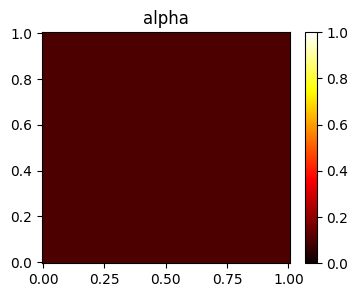

In [31]:
import numpy as np
import torch
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import time
import matplotlib.pyplot as plt
import matplotlib.axes
import torch.nn as nn
import os
import multiprocessing

# ================================================================
# ОБЩИЕ ПАРАМЕТРЫ
# ================================================================
Lx, Ly, T_final = 1.0, 1.0, 1.0

# Сетка по x, y
Nx, Ny = 100, 100
dx = Lx / (Nx - 1)
dy = Ly / (Ny - 1)

x = np.linspace(0, Lx, Nx)
y = np.linspace(0, Ly, Ny)
X, Y = np.meshgrid(x, y, indexing='ij')

# Для неявной схемы ограничение на dt отсутствует, задаём из соображений точности
Nt = 100
t = np.linspace(0, T_final, Nt)
dt = T_final / (Nt-1)

# ============ Начальное условие (типа колокол) ============
def gic(x: np.ndarray | torch.TensorType, y: np.ndarray | torch.TensorType):
    if isinstance(x, np.ndarray):
        return np.exp(-30 * ((x - 0.5)**2 + (y - 0.5)**2))
    else:
        return torch.exp(-30 * ((x - 0.5)**2 + (y - 0.5)**2))

# ============ Граничные условия (нулевые - холодные стенки) ============
def apply_bc(u):
    # левый-верхний угол  # вверх             # правый-верхний угол
    u[0, -1] = 0.0;       u[1:-1, -1] = 0.0;  u[-1, -1] = 0.0;
    # левая сторона                           # правая сторона
    u[0, 1:-1] = 0.0;                         u[-1, 1:-1] = 0.0;
    # левый-нижний угол   # низ               # правый-нижний угол
    u[0, 0] = 0.0;        u[1:-1, 0] = 0.0;   u[-1, 0] = 0.0
    return u

# ============= Строим одиночную карту ==========================
def plot2d(x_grid: np.ndarray, y_grid: np.ndarray, u_grid: np.ndarray, stitle: str):
    fig, ax = plt.subplots(figsize=(4, 3))
    img = ax.pcolormesh(x_grid, y_grid, u_grid, cmap="hot",
                        vmin = 0.0,
                        vmax=np.max(u_grid.all()))
    plt.colorbar(img, ax=ax)
    ax.set_title(stitle)
# ============= Строим карту по времени ==========================
def plot2d_times(x_grid: np.ndarray, y_grid: np.ndarray, solutions: list, times: list = [0.0, 0.25, 0.5, 0.75, 1.0], stitle: str=''):
    # ============ Визуализация в контрольные моменты ============
    fig, axes = plt.subplots(1, len(solutions), figsize=(4*len(solutions), 3))
    fig.suptitle(stitle)

    if len(solutions) == 1:
        axes = [axes]

    for ax, t, sol in zip(axes, times, solutions):
        #_plot2d_axes(x_grid=x_grid, y_grid=y_grid, u_grid=sol, stitle=f't = {t:.2f}', ax=ax)
        img = ax.contourf(x_grid, y_grid, sol, levels=100, cmap="hot",
                            vmin=0, #np.min(sol),
                            vmax=1, #np.max(sol))
                            )
        plt.colorbar(img, ax=ax)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_aspect("equal")
        ax.set_title(f"t={t:.2f}")

    plt.show()

# ============ Визуализируем начальное состояние ========================
# u = gic(X,Y)
# u = apply_bc(u)
# plot2d(x_grid=X, y_grid=Y, u_grid=u, stitle="Начальное тепловое состояние")

# Формируем матрицу коэффициентов теплопроводности
# ============================================================
# 2. Четыре области-квадрата 2x2 со своими alhpa
#    (границы раздела: x=0.5 и y=0.5)
# ============================================================
alpha = np.zeros((Nx, Ny))
alpha[(X <  0.5) & (Y <  0.5)] = 0.1     # левый-нижний
alpha[(X >= 0.5) & (Y <  0.5)] = 0.1    # правый-нижний
alpha[(X <  0.5) & (Y >= 0.5)] = 0.1   # левый-верхний
alpha[(X >= 0.5) & (Y >= 0.5)] = 0.1     # правый-верхний

np.random.seed(42)
#alpha = np.random.rand(Nx, Ny)/3.0
# ============================================================
# 3. Эффективная alpha на гранях — гармоническое среднее
# ============================================================
alpha_x_eff = 2*alpha[:-1,:]*alpha[1:,:]/(alpha[:-1,:]+alpha[1:,:])   # (Nx-1, Ny)
alpha_y_eff = 2*alpha[:,:-1]*alpha[:,1:]/(alpha[:,:-1]+alpha[:,1:])   # (Nx, Ny-1)

# ============ Визуализируем коэффициентов теплопроводности ==============
plot2d(x_grid=X, y_grid=Y, u_grid=alpha, stitle="alpha")

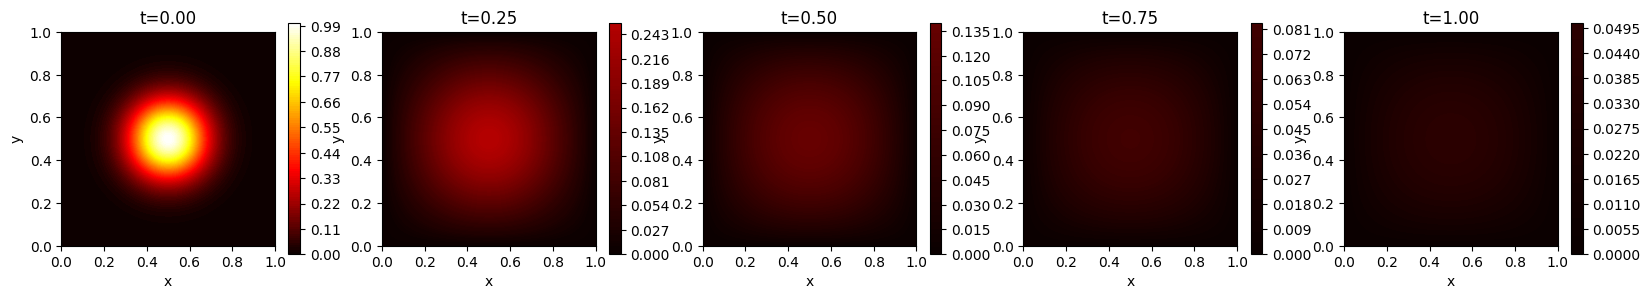

In [32]:
# Упорядочим неизвестные построчно: индекс k = i*Ny + j
# (i = 1..Nx-2, j = 1..Ny-2 - внутренние узлы)

ax_coef = alpha_x_eff * dt / dx**2
ay_coef = alpha_y_eff * dt / dy**2

# Разреженную матрицы системы M = I - dt*A будем представлять в виде 3-х векторов
rows, cols, data = [], [], []

# ================================================================
# НУМЕРАЦИЯ ВСЕХ УЗЛОВ (внутренних + граничных)
# ================================================================
def idx(i, j):
    """
    Линейный индекс idx для векторов rows, cols, data
    рассчитанный по индексам внутреннего узла M(i,j), i=0..Nx-1, j=0..Ny-1
    """
    return i * Ny + j

# упаковываем в три вектора согласно оператору M = I - dt*A (см.выше)
# узлы внутренней области: (1:Nx-2) x (1:Ny-2)
for i in range(Nx):
    for j in range(Ny):
        k = idx(i, j)

        if i==0 or i==(Nx-1) or j==0 or j==(Ny-1):
            # граничная строка: 1·u_k = g_k
            rows.append(k);
            cols.append(k);
            data.append(1.0)
            continue
        # внутренние узлы

        # alpha_x_eff[i,j] размерностью (Nx-1,Ny) эффективная \alhpa
        # между гранями (i,j) и (i+1,j), т.е. движемся вправо, узлов Nx,
        # граней Nx, аналогично
        # alpha_y_eff[i,j] размерностью (Nx, Ny-1) эффективная \alpha
        # между гранями (i,j) и (i,j+1), т.е. движемся вверх
        #
        # Для внутреннего узла (i,j) нужны 2 грани по х:
        # (i-1,j)-(i,j) и (i,j)-(i+1,j), т.е. alpha_x_eff[i-1,j] и alpha_x_eff[i,j]
        # и 2 грани по y:
        # (i,j-1)-(i,j) и (i,j)-(i,j+1), т.е. alpha_y_eff[i,j-1] и alpha_y_eff[i,j]
        #
        ax_w = ax_coef[i - 1, j]   # грань (i-1,j)-(i,j)
        ax_e = ax_coef[i,     j]   # грань (i,j)-(i+1,j)
        ay_s = ay_coef[i, j - 1]   # грань (i,j-1)-(i,j)
        ay_n = ay_coef[i, j    ]   # грань (i,j)-(i,j+1)
        # диагональ
        rows.append(k);
        cols.append(k)
        data.append(1.0 + ax_w + ax_e + ay_s + ay_n)
        # отрабатываем соседние узлы
        # сосед слева (i-1, j)
        rows.append(k);
        cols.append(idx(i - 1, j));
        data.append(-ax_w)
        # сосед справа (i+1, j)
        rows.append(k);
        cols.append(idx(i + 1, j));
        data.append(-ax_e)
        # сосед снизу (i, j-1)
        rows.append(k);
        cols.append(idx(i, j - 1));
        data.append(-ay_s)
        # сосед сверху (i, j+1)
        rows.append(k);
        cols.append(idx(i, j + 1));
        data.append(-ay_n)

M = sp.csr_matrix((data, (rows, cols)), shape=(Nx * Ny, Nx * Ny))
# M.shape - логический размер матрицы, при этом сами данные лежат в трех векторах
# M = sp.csr_matrix((data, (rows, cols)))
# print(f"Логический размер CSR-матрицы: {M.shape}, кол-во ненулевых элементов: {M.nnz}")

# LU разложение матрицы
# т.е. ур-ие вида Ax=b, решаем как PAQ=LU, где:
# P,Q - матрицы перестановок строк и столбцов
# L,U - нижне и верхне треугольные матрицы
# получаем объект SuperLU, у которого есть метод solve()
# для подстановки правой части b и есть .L, .U
solve = spla.splu(M.tocsc())

# ============ Решение по времени ============
fdm_save_times = [0.0, 0.25, 0.5, 0.75, 1.0]
# сюда сохраняем матрицу решений
fdm_solutions = []
# сюда записываем номер шага по времени
save_indices = [int(round(t / dt)) for t in fdm_save_times ]

# применяем начальные и граничные условия
u = gic(X,Y)
u = apply_bc(u)

for n in range(Nt + 1):
    if n in save_indices:
        fdm_solutions.append(u.copy())
    if n == Nt:
        break
    # правая часть - текущее решение во внутренних узлах
    # вытягиваем матрицу в вектор, order="C" - порядок языка СИ
    # т.е. в u[i,j] идем вначале по j, потом по i
    b = u.reshape(-1, order="C")
    # решаем СЛАУ, где b = u^{n}, sol=u^{n+1}
    sol = solve.solve(b)
    # обновляем внутренние узлы
    # обратная операция перепаковываем вектор в матрицу
    u = sol.reshape((Nx, Ny), order="C")
    # граничные условия
    u = apply_bc(u)

# ============ Визуализация в контрольные моменты ============
plot2d_times(x_grid=X, y_grid=Y, solutions=fdm_solutions, times = fdm_save_times, stitle='')

## ШАГ 2 - Physics-Informed Neural Networks (PINNs)

Теоретическая основа: универсальная теорема аппроксимации (доказана Джорджем Цибенко в 1989 году и Куртом Хорником в 1991): однослойная нейроная сеть с достаточно большим числом нейронов и нелинейной гладкой функцией \
(например, sigmoid или tanh) может приблизить любую непрерывную функцию на компактном множестве \
с любой заданной точностью.

$$
sup_{x \in K}| f(x) - N(x) | < \epsilon
$$

## Прямая задача аппроксимация дифференциального уравнения нейроной сетью
Пусть $ N_u(x,y,t) $ - нейросеть, которая аппроксимирует u(x,y,t),тогда аппроксимированное ур-ие теплопроводности примет вид:

$$
\frac{\partial N_u(x,y,t)}{\partial t}=k(\frac{\partial^2 N_u(x,y,t)}{\partial x^2}+\frac{\partial^2 N_u(x,y,t)}{\partial y^2})
$$
где: k - для данной прямой задачи постоянный коэффициент

Пусть также $ N_u(x,y,t) $, состоящая, например, из входа -> два внутренних слоя -> выход -
это гладкая функция как композиция слоев нейросети: \
$$ N_u(x,y,t) = f_3(f_2(f_1(x,y,t,\theta_1), \theta_2), \theta_3), $$ \
$ f_1, f_2, f_3 $ - слои нейросети (линейные преобразования + функции активации) \
$ \theta_i $ - обучаемые параметры (веса и смещения) \
производная $  N_u(x,y,t) $ вычисляется по цепному правилу, например, по х:
$$
\frac{\partial N_u}{\partial x} = \frac{\partial f_3}{\partial f_2} * \frac{\partial f_2}{\partial f_1} * \frac{\partial f_1}{\partial x}
$$
где каждый член произведения это якобиан (матрица частных производных)

## Функция потерь (loss function)
### 1. Partial Differential Equation loss: ошибка аппроксимации дифф.ур-ия нейронной сетью
$$
L_{PDE} = \frac{1}{M} \sum_{j=1}^M || \frac{\partial N_u(x,y,t)}{\partial t} - k(\frac{\partial^2 N_u(x,y,t)}{\partial x^2} + \frac{\partial^2 N_u(x,y,t)}{\partial y^2}) ||^2
$$
$$ x,y \in (0,L)*(0,L), t \in (0,T] $$
### 2. Initial condition loss: ошибка нейронной сети по начальным условиям
$$ L_{IC} = \frac{1}{K} \sum_{j=1}^K || N_u(x,y,0) - g_{IC}(x,y) ||^2 $$
$$ x,y \in [0,L]*[0,L], t = 0 $$
### 3. Boundary condition loss: ошибка нейронной сети по граничным условиям
$$ L_{BC} = \frac{1}{P} (\sum_{j=1}^P || N_u(0,y,t) - g_{LB}(t) ||^2 + \sum_{j=1}^P || N_u(L,y,t) - g_{RB}(t) ||^2 + \sum_{j=1}^P || N_u(x,0,t) - g_{DB}(t) ||^2 + \sum_{j=1}^P || N_u(x,L,t) - g_{UB}(t) ||^2) $$
$$ x \in \{0,L\}, y \in \{0,L\}, t \in (0,T] $$
### Итоговый лосс:
$$ L = \lambda_{PDE} L_{PDE} + \lambda_{IC} L_{IC} + \lambda_{BC} L_{BC} $$

In [33]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Logical CPUs:', os.cpu_count())
print('multiprocessing:', multiprocessing.cpu_count())

torch.set_num_threads(multiprocessing.cpu_count())
print(f'device = {device}')

Logical CPUs: 2
multiprocessing: 2
device = cpu


In [34]:
# ==================== class Nu ================================================
class Nu( nn.Module ):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(3,128),
            nn.Tanh(),
            nn.Linear(128,128),
            nn.Tanh(),
            nn.Linear(128,128),
            nn.Tanh(),
            nn.Linear(128,128),
            nn.Tanh(),
            nn.Linear(128,1)
        )

    def forward(self, x: torch.tensor, y: torch.tensor, t: torch.tensor):
        return self.fc( torch.cat([x, y, t], dim=1) )

#============================ Точки коллоации =================================
def build_collocation_points(n_pde: int=10000, n_bc: int=5000, n_ic: int=2000):
  '''
  Функция создания точек коллокаций в заданом кубе: [1,1,1]

  Parameters:
    n_pde,n_bc,n_ic - кол-во случайных точек по х,y,t

  Return:
    кортеж(кортеж_нач_усл, кортеж_гр_усл, кортеж_внутр_обл)
  каждый из внутренних кортежей имеет структру: (x, y, t)
  каждый из которых является вектор-столбом - torch.tensor.view(-1,1)
  '''
  # точки коллокации для начальных условий (x,y,0)
  points_ic = (torch.rand(n_ic, 1, requires_grad=True, dtype=torch.double, device=device),
               torch.rand(n_ic, 1, requires_grad=True, dtype=torch.double, device=device),
               torch.zeros(n_ic, 1, requires_grad=True, dtype=torch.double, device=device))
  # точки коллокации для граничных условий
  x = torch.rand(n_bc, 1, requires_grad = True, dtype=torch.double, device=device)
  y = torch.rand(n_bc, 1, requires_grad = True, dtype=torch.double, device=device)
  t = torch.rand(n_bc, 1, requires_grad = True, dtype=torch.double, device=device)

  border_selector = torch.randint(0, 4, (n_bc, 1))
  with torch.no_grad():
    x[border_selector == 0] = 0.0   # Левая грань, device=device
    x[border_selector == 1] = 1.0   # Правая грань
    y[border_selector == 2] = 0.0   # Нижняя грань
    y[border_selector == 3] = 1.0   # Верхняя грань

  points_bc = (x, y, t)
  # точки коллокации для внутренней области (x,y,t)
  points_pde = (torch.rand(n_pde, 1, requires_grad=True, dtype=torch.double, device=device),
                torch.rand(n_pde, 1, requires_grad=True, dtype=torch.double, device=device),
                torch.rand(n_pde, 1, requires_grad=True, dtype=torch.double, device=device))

  return (points_pde, points_bc, points_ic)

#============== Функция генерирующая граничные условия по векторам (x,y,t) =====
def gbc(x: torch.TensorType, y: torch.TensorType, t: torch.TensorType):
  return torch.zeros_like(x, device=device)

#points_pde, points_bc, points_ic = build_collocation_points(n_pde = 3000, n_bc=5000, n_ic=10000)

In [35]:
#============================= Градиентная функция ===========================
def gradients(u: torch.TensorType, x: torch.TensorType):
  return torch.autograd.grad(outputs=u, inputs=x, grad_outputs=torch.ones_like(u, device=device), create_graph=True, retain_graph=True)[0]

#============================= Обучение Nu прямая задача =====================
def train_pinn_direct(points_pde: torch.TensorType, points_bc: torch.TensorType,
                      points_ic: torch.TensorType, alpha: float, num_epochs: int=1000):

  u_net = Nu().double().to(device)
  opt = torch.optim.Adam( u_net.parameters(), lr=1e-3 )
  mse_loss = nn.MSELoss()

  # весовые коэффициенты для loss
  w_pde, w_ic, w_bc = 1.,1.,1.

  loss_history = {'pde': [], 'ic': [], 'bc': [], 'data':[]}

  for epoch in range(num_epochs):
      start = time.perf_counter()
      # стираем предыдущий граф градиента
      opt.zero_grad()
      # ---------------------------------- LOSS PDE ----------------
      u_pred_pde = u_net(points_pde[0], points_pde[1], points_pde[2])

      u_x = gradients(u_pred_pde, points_pde[0])
      u_y = gradients(u_pred_pde, points_pde[1])
      u_t = gradients(u_pred_pde, points_pde[2])

      u_xx = gradients(u_x, points_pde[0])
      u_yy = gradients(u_y, points_pde[1])

      loss_pde = mse_loss( u_t - alpha*(u_xx + u_yy), torch.zeros_like(u_t, device=device))
      # ---------------------------------- LOSS IC -----------------
      u_pred_ic = u_net(points_ic[0], points_ic[1], points_ic[2])
      loss_ic = mse_loss(u_pred_ic, gic(points_ic[0], points_ic[1]))
      # ---------------------------------- LOSS BC -----------------
      u_pred_bc = u_net(points_bc[0], points_bc[1], points_bc[2])
      loss_bc = mse_loss(u_pred_bc, gbc(points_bc[0], points_bc[1], points_bc[2]))
      # ---------------------------------- LOSS COMMON -------------
      loss = w_pde * loss_pde + w_ic * loss_ic + w_bc * loss_bc

      loss.backward()
      opt.step()

      loss_history['ic'].append(loss_ic.item())
      loss_history['bc'].append(loss_bc.item())
      loss_history['pde'].append(loss_pde.item())
      # не используется здесь
      loss_history['data'].append(0)

      if epoch % 20 == 0:
          print(f'Epoch [{epoch}/{num_epochs}], Loss: {loss.item():.8f},'
            f' loss pde: {loss_pde.item():.8f}, loss ic: {loss_ic.item():.8},'
            f' loss bc: {loss_bc.item():.8f}, time: {(time.perf_counter() - start):.8f}')
      if loss < 1e-4:
          print('stop optimization')
          break
  return u_net, loss_history

# ============================== График лоссов =================================
def plot_loss_history(loss_history: dict, step: int=200):
    epochs = range(0, len(loss_history['pde']), step)

    plt.plot(epochs, loss_history['pde'][::step], label='PDE Loss')
    plt.plot(epochs, loss_history['bc'][::step], label='BC Loss')
    plt.plot(epochs, loss_history['ic'][::step], label='IC Loss')
    plt.plot(epochs, loss_history['data'][::step], label='DATA Loss')

    plt.yscale('log')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid()
    plt.legend()
    plt.show()


Epoch [0/1000], Loss: 0.04972237, loss pde: 0.00005232, loss ic: 0.04822155, loss bc: 0.00144850, time: 0.64224539
Epoch [20/1000], Loss: 0.04777534, loss pde: 0.00000980, loss ic: 0.044470631, loss bc: 0.00329491, time: 0.65968773
Epoch [40/1000], Loss: 0.04698215, loss pde: 0.00030618, loss ic: 0.043938642, loss bc: 0.00273732, time: 0.61815643
Epoch [60/1000], Loss: 0.04629645, loss pde: 0.00028508, loss ic: 0.04381681, loss bc: 0.00219457, time: 0.65511814
Epoch [80/1000], Loss: 0.04407707, loss pde: 0.00025477, loss ic: 0.042145807, loss bc: 0.00167650, time: 0.65569958
Epoch [100/1000], Loss: 0.03974097, loss pde: 0.00104428, loss ic: 0.036233515, loss bc: 0.00246318, time: 0.66920269
Epoch [120/1000], Loss: 0.03681448, loss pde: 0.00046889, loss ic: 0.03470888, loss bc: 0.00163671, time: 1.90461336
Epoch [140/1000], Loss: 0.03407493, loss pde: 0.00067181, loss ic: 0.031914127, loss bc: 0.00148899, time: 0.66229494
Epoch [160/1000], Loss: 0.03289884, loss pde: 0.00073407, loss ic

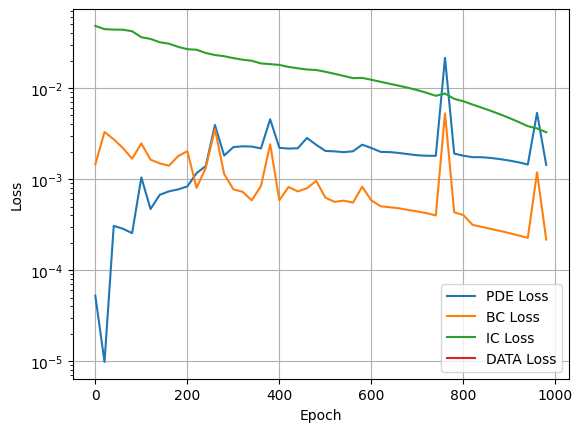

In [36]:
# Обучение PINN
points_pde, points_bc, points_ic = build_collocation_points(n_pde = 3000, n_bc=5000, n_ic=10000)
%time u_net, loss_history = train_pinn_direct(points_pde, points_bc, points_ic, alpha = 0.1, num_epochs=1000)
# Строим график лоссов
plot_loss_history(loss_history, 20)

In [37]:
# ================ Хот - карты для FDM, PINN, |FDM-PINN| ===========
def plot_fdm_hots(x_grid: np.ndarray, y_grid: np.ndarray, fdm_solutions: list, fdm_times: list):
  print('========================================== FDM ======================================================================')
  plot2d_times(x_grid, y_grid, fdm_solutions, fdm_times)

def plot_pinn_hots(x_grid: np.ndarray, y_grid: np.ndarray, fdm_solutions: list, fdm_times: list, u_net: nn.Module):
  solutions = []
  for t in fdm_times:
      # инференс
      u_pred = u_net(torch.tensor(x_grid, device=device).view(-1,1),
                    torch.tensor(y_grid, device=device).view(-1,1),
                    torch.ones_like(torch.tensor(x_grid, device=device).view(-1,1))*t )
      # вектор u_pred представляем в виде матрицы x_grid.shape
      solutions.append(u_pred.view(x_grid.shape).cpu().detach().numpy())

  print('========================================== PINN ======================================================================')
  plot2d_times(x_grid, y_grid, solutions, fdm_times)

def plot_fdm_minus_pinn_hots(x_grid: np.ndarray, y_grid: np.ndarray, fdm_solutions: list, fdm_times: list, u_net: nn.Module):
  diff = []
  for i in range(len(fdm_times)):
      # инференс
      u_pred = u_net(torch.tensor(x_grid, device=device).view(-1,1),
                    torch.tensor(y_grid, device=device).view(-1,1),
                    torch.ones_like(torch.tensor(x_grid, device=device).view(-1,1))*fdm_times[i] )
      # вектор u_pred представляем в виде матрицы x_grid.shape
      #pinn_solutions.append(u_pred.view(x_grid.shape).detach().numpy())
      delta = np.abs(u_pred.view(x_grid.shape).detach().cpu().numpy()-fdm_solutions[i])
      diff.append(delta)
  print('==========================================  | FDM - PINN| ======================================================================')
  plot2d_times(x_grid, y_grid, diff, fdm_times)

#plot_fdm_hots(X, Y, fdm_solutions, fdm_save_times)
#plot_pinn_hots(X, Y, fdm_solutions, fdm_save_times, u_net)
#plot_fdm_minus_pinn_hots(X, Y, fdm_solutions, fdm_save_times, u_net)

========================================== FDM ======================================================================


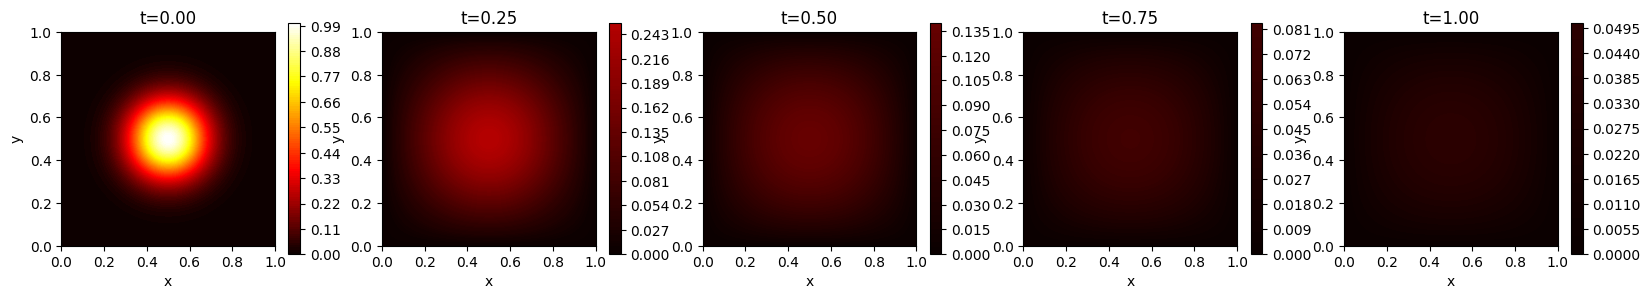

In [38]:
plot_fdm_hots(X, Y, fdm_solutions, fdm_save_times)

========================================== PINN ======================================================================


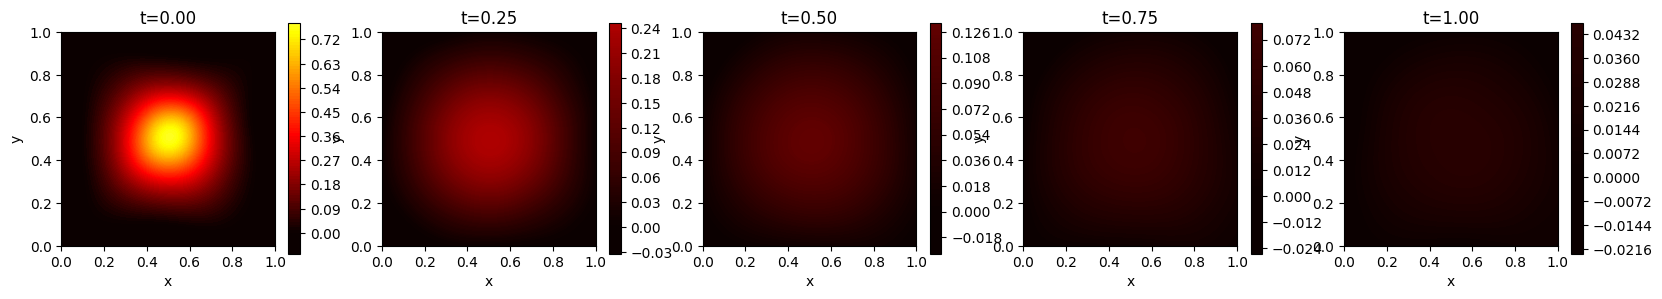

In [39]:
plot_pinn_hots(X, Y, fdm_solutions, fdm_save_times, u_net)

==========================================  | FDM - PINN| ======================================================================


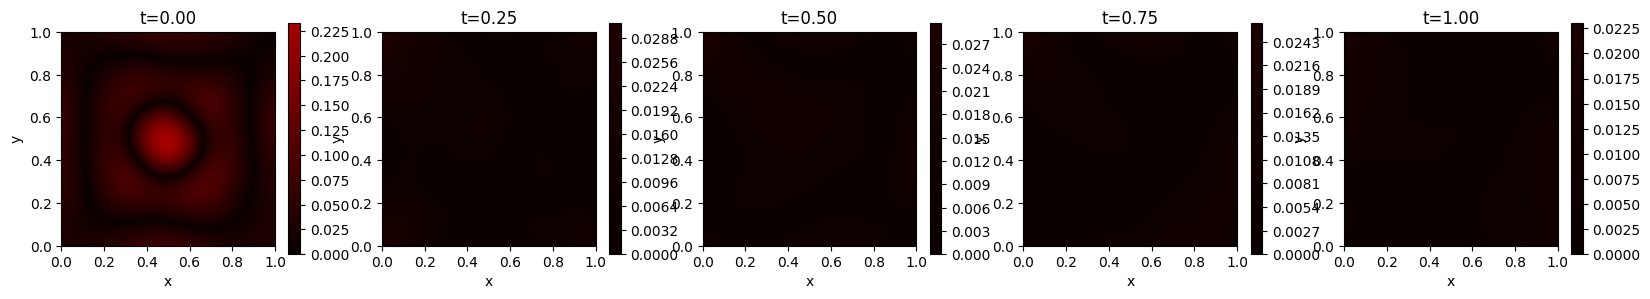

In [40]:
plot_fdm_minus_pinn_hots(X, Y, fdm_solutions, fdm_save_times, u_net)

# ШАГ 3.1


В итоговый лосс добавится лосс по данным:

$$ L = \lambda_{PDE} L_{PDE} + \lambda_{IC} L_{IC} + \lambda_{BC} L_{BC} + \lambda_{DATA}L_{DATA}$$

где:

$$
L_{DATA}=\frac{1}{H}\sum_{i=1}^H || N_u(x_i,y_i,t_i) - u^{obs}(x_i,y_i,t_i) ||^2
$$

$ u^{obs} $ - наблюдаемые данные в некоторых точках $ (x_i,y_i,t_i) $, что и прогноз модели


In [41]:
#====================== Функция генерации синтетических наблюдаемых данных по ранее полученному решению FDM ===================
def build_observation_points_by_fdm(x_grid: np.ndarray, y_grid: np.ndarray,
                                    fdm_solutions: list, fdm_tlayers: list, npoints: int):
  '''
  Parameters
  ----------
    solutions: list
      список МКР-решений:
  Return
  ----------

  '''
  x_obs = np.array([ x_grid for _ in fdm_solutions ]).reshape(-1,1)
  y_obs = np.array([ y_grid for _ in fdm_solutions ]).reshape(-1,1)
  t_obs = np.array([ (np.ones_like(x_obs)*t) for t in fdm_tlayers]).reshape(-1,1)
  u_obs = np.array([ sol for sol in fdm_solutions ]).reshape(-1,1)

  # индексы n случайных элементов
  indx = np.random.randint(0, x_obs.shape[0], x_obs.shape[0])[0:npoints]
  x_obs = x_obs[ indx ]
  y_obs = y_obs[ indx ]
  t_obs = t_obs[ indx ]
  u_obs = u_obs[ indx ]

  # точки наблюдений (x,y,u)
  points_obs = (torch.tensor(x_obs, requires_grad=True, dtype=torch.double, device=device),
                torch.tensor(y_obs, requires_grad=True, dtype=torch.double, device=device),
                torch.tensor(t_obs, requires_grad=True, dtype=torch.double, device=device),
                torch.tensor(u_obs, requires_grad=True, dtype=torch.double, device=device))

  return points_obs

#pointds_obs = build_observation_points_by_fdm(x_grid = X, y_grid = Y, fdm_solutions = fdm_solutions, fdm_tlayers = fdm_save_times, npoints = 100)
#pointds_obs[0].shape

In [42]:
#=========================== Обучение Nu,k обратная задача ===================
def train_pinn_back_kconst(points_pde: torch.TensorType, points_bc: torch.TensorType,
                           points_ic: torch.TensorType, points_obs: torch.TensorType,
                           alpha_beg: float=1.0, num_epochs: int=1000):

  #alpha = torch.exp(alpha_beg)
  alpha = torch.tensor(alpha_beg, requires_grad=True, device=device)

  u_net = Nu().double().to(device)

  #opt_u = torch.optim.Adam(u_net.parameters(), lr=1e-3)
  opt_u = torch.optim.Adam([{'params': u_net.parameters(), 'lr': 1e-3},
                            {'params': [alpha], 'lr': 1e-2} ])

  mse_loss = nn.MSELoss()

  # весовые коэффициенты для общего loss
  w_pde, w_ic, w_bc, w_data = 1.0, 1.0, 1.0, 1.0

  loss_history = {'pde':[],'ic':[],'bc':[],'data':[]}

  for epoch in range(num_epochs):
      start = time.perf_counter()
      opt_u.zero_grad()
      # ---------------------------------- LOSS PDE ----------------
      u_pred_pde = u_net(points_pde[0], points_pde[1], points_pde[2])

      u_x = gradients(u_pred_pde, points_pde[0])
      u_y = gradients(u_pred_pde, points_pde[1])
      u_t = gradients(u_pred_pde, points_pde[2])

      u_xx = gradients(u_x, points_pde[0])
      u_yy = gradients(u_y, points_pde[1])

      loss_pde = mse_loss( u_t - alpha*(u_xx + u_yy), torch.zeros_like(u_t, device=device))
      # ---------------------------------- LOSS IC -----------------
      u_pred_ic = u_net(points_ic[0], points_ic[1], points_ic[2])
      loss_ic = mse_loss(u_pred_ic, gic(points_ic[0], points_ic[1]))
      # ---------------------------------- LOSS BC -----------------
      u_pred_bc = u_net(points_bc[0], points_bc[1], points_bc[2])
      loss_bc = mse_loss(u_pred_bc, gbc(points_bc[0], points_bc[1], points_bc[2]))
      # ---------------------------------- LOSS DATA ---------------
      # прогноз модели по наблюдаемым (x,y,t)
      u_data_pred = u_net(points_obs[0], points_obs[1], points_obs[2])
      # наблюдаемые, например, синтетические МКР или экспериментальные, значения по (x,y,t)
      u_data_obs  = points_obs[3]
      # лосс по данным
      loss_data = mse_loss(u_data_pred, u_data_obs)
      # ---------------------------------- LOSS COMMON -------------
      loss = w_pde * loss_pde + w_ic * loss_ic + w_bc * loss_bc + w_data * loss_data

      loss.backward()
      opt_u.step()

      loss_history['ic'].append(loss_ic.item())
      loss_history['bc'].append(loss_bc.item())
      loss_history['pde'].append(loss_pde.item())
      loss_history['data'].append(loss_data.item())

      if epoch % 20 == 0:
          print(f'Epoch [{epoch}/{num_epochs}], Loss: {loss.item():.8f},'
                f' loss pde: {loss_pde.item():.8f}, loss ic: {loss_ic.item():.8},'
                f' loss bc: {loss_bc.item():.8f},'
                f' loss data: {loss_data.item():.8f},'
                f' time: {(time.perf_counter() - start):.8f}')
      if loss < 1e-4:
          print('stop optimization')
          break

  return u_net, alpha, loss_history

Epoch [0/1000], Loss: 0.09349779, loss pde: 0.00134962, loss ic: 0.066013452, loss bc: 0.00424631, loss data: 0.02188840, time: 0.69088085
Epoch [20/1000], Loss: 0.05074715, loss pde: 0.00018176, loss ic: 0.041022609, loss bc: 0.00150484, loss data: 0.00803794, time: 0.65464971
Epoch [40/1000], Loss: 0.04992369, loss pde: 0.00020093, loss ic: 0.040784688, loss bc: 0.00100487, loss data: 0.00793319, time: 1.42805972
Epoch [60/1000], Loss: 0.04922827, loss pde: 0.00027712, loss ic: 0.039645384, loss bc: 0.00120673, loss data: 0.00809904, time: 0.65862942
Epoch [80/1000], Loss: 0.04898161, loss pde: 0.00008970, loss ic: 0.039482394, loss bc: 0.00125675, loss data: 0.00815276, time: 0.67468453
Epoch [100/1000], Loss: 0.04879414, loss pde: 0.00007843, loss ic: 0.039447821, loss bc: 0.00118691, loss data: 0.00808098, time: 0.66689181
Epoch [120/1000], Loss: 0.04853044, loss pde: 0.00007784, loss ic: 0.039235001, loss bc: 0.00117070, loss data: 0.00804690, time: 0.65344742
Epoch [140/1000], L

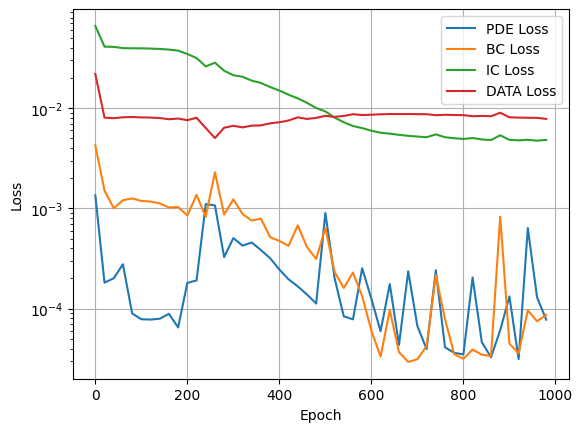

In [45]:
# генерируем точки коллокации для pde, bc, ic
points_pde, points_bc, points_ic = build_collocation_points(n_pde = 3000, n_bc=5000, n_ic=10000)
# фильтруем точки (x,y) и решение (u), ранее полученное с FDM, по временным слоям (t)
# итого получаем точки наблюдений (x,y,t,u) для решения обратной задачи
points_obs = build_observation_points_by_fdm(x_grid = X, y_grid = Y,
                                             fdm_solutions = fdm_solutions,
                                             fdm_tlayers = fdm_save_times,
                                             npoints = 100)
# Обучение PINN back
%time u_net, alpha_const, loss_history = train_pinn_back_kconst(points_pde = points_pde, points_bc = points_bc, points_ic = points_ic, points_obs = points_obs, alpha_beg = 1.5, num_epochs=1000)
# Строим график лоссов
plot_loss_history(loss_history, 20)

In [ ]:
alpha_const

In [ ]:
plot_fdm_hots(X, Y, fdm_solutions, fdm_save_times)

In [ ]:
plot_pinn_hots(X, Y, fdm_solutions, fdm_save_times, u_net)

In [ ]:
plot_fdm_minus_pinn_hots(X, Y, fdm_solutions, fdm_save_times, u_net)

# ШАГ 3.2
## Аппроксимируем коэф.теплопроводности PINN-ом

Пусть $ k=N_k(x,y)=N_k $ - нейросеть, которая аппроксимирует коэффициент теплопроводности k(x,y), $ N_u(x,y,t)=N_u $ тогда аппроксимированное ур-ие теплопроводности примет вид:

$$
\frac{\partial N_u}{\partial t}=\frac{\partial}{\partial x}(N_k\frac{\partial N_u}{\partial x})+\frac{\partial}{\partial y}(N_k\frac{\partial N_u}{\partial y})
$$

раскрываем:

$$
\frac{\partial N_u}{\partial t}=N_k(\frac{\partial^2 N_u}{\partial x^2}+\frac{\partial^2 N_u}{\partial y^2}) + \frac{\partial N_k}{\partial x}\frac{\partial N_u}{\partial x} + \frac{\partial N_k}{\partial y}\frac{\partial N_u}{\partial y}
$$

В итоговый лосс добавится лосс по данным:

$$ L = \lambda_{PDE} L_{PDE} + \lambda_{IC} L_{IC} + \lambda_{BC} L_{BC} + \lambda_{DATA}L_{DATA}$$

где:

$$
L_{DATA}=\frac{1}{H}\sum_{i=1}^H || N_u(x_i,y_i,t_i) - u^{obs}(x_i,y_i,t_i) ||^2
$$

$ u^{obs} $ - наблюдаемые данные в некоторых точках $ (x_i,y_i,t_i) $, что и прогноз модели


In [ ]:
#======================= class Nk ==============================================
class Nk( nn.Module ):
    def __init__(self, k_min: float = 0.005, k_max: float = 10.0):
        super().__init__()
        self.k_min, self.k_max = k_min, k_max
        self.fc = nn.Sequential(
            nn.Linear(2,128),
            nn.Tanh(),
            nn.Linear(128,128),
            nn.Tanh(),
            nn.Linear(128,1)
        )

    def forward(self, x: torch.tensor, y: torch.tensor):
        #return self.fc( torch.cat([x, y], dim=1) )
        # Ограничение на уловие положительности k>0
        raw = self.fc(torch.cat([x, y], dim=1))
        k = self.k_min + (self.k_max - self.k_min) * torch.sigmoid(raw)
        # k = F.softplus(raw) + 1e-3   # k > 0
        return k

#k_net = Nk()
#k = k_net(torch.tensor([0.5]).view(-1,1), torch.tensor([0.5]).view(-1,1))

In [ ]:
#=========================== Обучение Nu, Nk обратная задача ===================
def train_pinn_back(points_pde: torch.TensorType, points_bc: torch.TensorType,
                    points_ic: torch.TensorType, points_obs: torch.TensorType, num_epochs: int=1000):
  u_net = Nu().double().to(device)
  k_net = Nk().double().to(device)

  # проверка что у 2-х сетей нет общих параметров
  assert len(set(map(id, u_net.parameters())) & set(map(id, k_net.parameters()))) == 0

  opt_u = torch.optim.Adam( u_net.parameters(), lr=1e-3 )
  opt_k = torch.optim.Adam( k_net.parameters(), lr=5e-4 )

  mse_loss = nn.MSELoss()

  # весовые коэффициенты для общего loss
  w_pde, w_ic, w_bc, w_data = 1.0, 1.0, 1.0, 1.0

  loss_history = {'pde': [],
                  'ic': [],
                  'bc': [],
                  'data':[]}

  for epoch in range(num_epochs):
      start = time.perf_counter()
      # стираем предыдущий граф градиента
      opt_u.zero_grad()
      opt_k.zero_grad()
      # ---------------------------------- LOSS PDE ----------------
      u_pred_pde = u_net(points_pde[0], points_pde[1], points_pde[2])
      k_pred_pde = k_net(points_pde[0], points_pde[1])

      u_x = gradients(u_pred_pde, points_pde[0])
      u_y = gradients(u_pred_pde, points_pde[1])
      u_t = gradients(u_pred_pde, points_pde[2])

      u_xx = gradients(u_x, points_pde[0])
      u_yy = gradients(u_y, points_pde[1])

      k_x  = gradients(k_pred_pde, points_pde[0])
      k_y  = gradients(k_pred_pde, points_pde[1])

      loss_pde = mse_loss(u_t - k_pred_pde*(u_xx + u_yy) - k_x*u_x - k_y*u_y, torch.zeros_like(u_t, device=device))
      # ---------------------------------- LOSS IC -----------------
      u_pred_ic = u_net(points_ic[0], points_ic[1], points_ic[2])
      loss_ic = mse_loss(u_pred_ic, gic(points_ic[0], points_ic[1]))
      # ---------------------------------- LOSS BC -----------------
      u_pred_bc = u_net(points_bc[0], points_bc[1], points_bc[2])
      loss_bc = mse_loss(u_pred_bc, gbc(points_bc[0], points_bc[1], points_bc[2]))
      # ---------------------------------- LOSS DATA ---------------
      # прогноз модели по наблюдаемым (x,y,t)
      u_data_pred = u_net(points_obs[0], points_obs[1], points_obs[2])
      # наблюдаемые, например, синтетические МКР или экспериментальные, значения по (x,y,t)
      u_data_obs  = points_obs[3]
      # лосс по данным
      loss_data = mse_loss(u_data_pred, u_data_obs)
      # ---------------------------------- LOSS COMMON -------------
      loss = w_pde * loss_pde + w_ic * loss_ic + w_bc * loss_bc + w_data * loss_data

      loss.backward()

      opt_u.step()
      opt_k.step()

      loss_history['ic'].append(loss_ic.item())
      loss_history['bc'].append(loss_bc.item())
      loss_history['pde'].append(loss_pde.item())
      loss_history['data'].append(loss_data.item())

      if epoch % 20 == 0:
          print(f'Epoch [{epoch}/{num_epochs}], Loss: {loss.item():.8f},'
                f' loss pde: {loss_pde.item():.8f}, loss ic: {loss_ic.item():.8},'
                f' loss bc: {loss_bc.item():.8f}, loss data: {loss_data.item():.8f},'
                f' time: {(time.perf_counter() - start):.8f}')
      if loss < 1e-4:
          print('stop optimization')
          break

  return u_net, k_net, loss_history

In [ ]:
# генерируем точки коллокации для pde, bc, ic
points_pde, points_bc, points_ic = build_collocation_points(n_pde = 3000, n_bc=5000, n_ic=10000)
# фильтруем точки (x,y) и решение (u), ранее полученное с FDM, по временным слоям (t)
# итого получаем точки наблюдений (x,y,t,u) для решения обратной задачи
points_obs = build_observation_points_by_fdm(x_grid = X, y_grid = Y,
                                             fdm_solutions = fdm_solutions,
                                             fdm_tlayers = fdm_save_times, npoints = 1000)
# Обучение PINN back
%time u_net, k_net, loss_history = train_pinn_back(points_pde = points_pde, points_bc = points_bc, points_ic = points_ic, points_obs = points_obs, num_epochs=1000)
# Строим график лоссов
plot_loss_history(loss_history, 20)

In [ ]:
# ============ Визуализируем коэффициентов теплопроводности FDM ==============
plot2d(x_grid=X, y_grid=Y, u_grid=alpha, stitle=f'k-fdm: {alpha.min():.5f} : {alpha.max():.5f}')

In [ ]:
# ============ Визуализируем коэффициентов теплопроводности PINN back ==============
alpha_pinn_back = k_net(torch.tensor(X, device=device).view(-1,1), torch.tensor(Y, device=device).view(-1,1))
plot2d(x_grid=X, y_grid=Y, u_grid=alpha_pinn_back.view(X.shape).cpu().detach().numpy(), stitle=f'k-pinn: {alpha_pinn_back.min():.5f} : {alpha_pinn_back.max():.5f}')

In [ ]:
plot_fdm_hots(X, Y, fdm_solutions, fdm_save_times)

In [ ]:
plot_pinn_hots(X, Y, fdm_solutions, fdm_save_times, u_net)

In [ ]:
plot_pinn_hots(X, Y, fdm_solutions, fdm_save_times, u_net)